<a href="https://colab.research.google.com/github/isharawat-01/BigData-practical/blob/main/mnist_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from pathlib import Path

Load the MNIST dataset

In [ ]:
dataset_url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
dataset_path = Path("mnist.npz")

if not dataset_path.exists():
    urllib.request.urlretrieve(dataset_url, dataset_path)
print("Dataset file is ready.")

Dataset file is ready.


In [ ]:
with np.load("mnist.npz") as dataset:
    train_images = dataset["x_train"]
    train_labels = dataset["y_train"]
    test_images = dataset["x_test"]
    test_labels = dataset["y_test"]

print("Training set:", train_images.shape, train_labels.shape)
print("Testing set:", test_images.shape, test_labels.shape)
print("Label for sample 12:", train_labels[12])

Training set: (60000, 28, 28) (60000,)
Testing set: (10000, 28, 28) (10000,)
Label for sample 12: 3


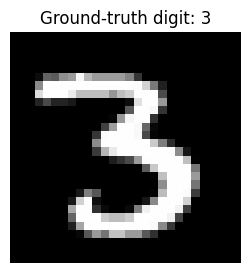

In [ ]:
sample_id = 12
plt.figure(figsize=(3, 3))
plt.imshow(train_images[sample_id], cmap="gray")
plt.title(f"Ground-truth digit: {train_labels[sample_id]}")
plt.axis("off")
plt.show()

In [ ]:
print("Image array dimensions:", train_images.shape)
print(f"Raw intensity range: {train_images.min()} to {train_images.max()}")
print("Digit classes:", np.unique(train_labels))

Image array dimensions: (60000, 28, 28)
Raw intensity range: 0 to 255
Digit classes: [0 1 2 3 4 5 6 7 8 9]



Normalize pixel values


In [ ]:
# Keep the original arrays as uint8; create normalized copies for visualization/processing.
train_norm = train_images.astype(np.float32) / 255.0
test_norm = test_images.astype(np.float32) / 255.0

print("Normalized minimum:", train_norm.min())
print("Normalized maximum:", train_norm.max())

Normalized minimum: 0.0
Normalized maximum: 1.0


Single image dimensions: (28, 28)
Normalized intensity range: 0.0 to 1.0


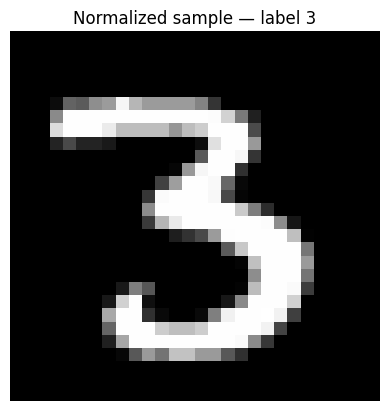

In [ ]:
sample_id = 12
digit_float = train_norm[sample_id]

print("Single image dimensions:", digit_float.shape)
print("Normalized intensity range:", digit_float.min(), "to", digit_float.max())

plt.imshow(digit_float, cmap="gray", vmin=0, vmax=1)
plt.title(f"Normalized sample — label {train_labels[sample_id]}")
plt.axis("off")
plt.show()

Gaussian smoothing

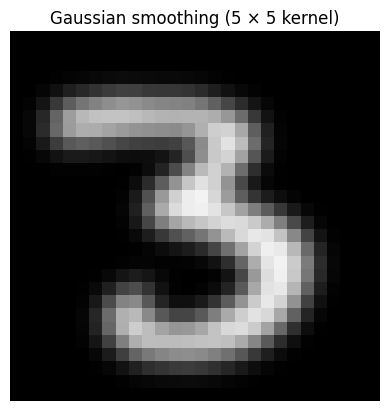

In [ ]:
smooth_digit = cv2.GaussianBlur(digit_float, (5, 5), sigmaX=0)

plt.imshow(smooth_digit, cmap="gray", vmin=0, vmax=1)
plt.title("Gaussian smoothing (5 × 5 kernel)")
plt.axis("off")
plt.show()

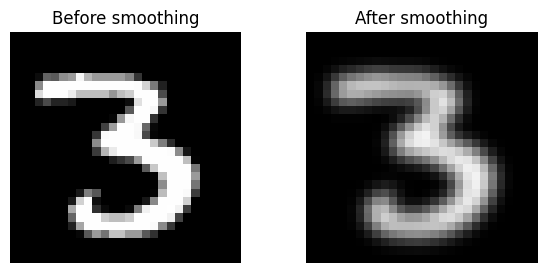

<Figure size 640x480 with 0 Axes>

In [ ]:
smooth_digit = cv2.GaussianBlur(digit_float, (5, 5), 0)
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(digit_float, cmap="gray", vmin=0, vmax=1)
plt.title("Before smoothing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(smooth_digit, cmap="gray", vmin=0, vmax=1)
plt.title("After smoothing")
plt.axis("off")

plt.show()
plt.tight_layout()
plt.show()

Shift an image (translation)

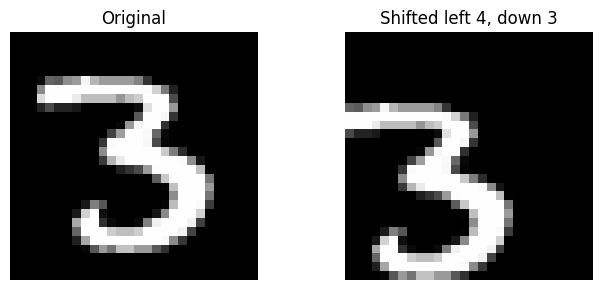

In [ ]:
def shift_image(gray_image, shift_x=0, shift_y=0):
    #Translate an image by the requested number of pixels.
    h, w = gray_image.shape[:2]
    transform = np.array([[1, 0, shift_x], [0, 1, shift_y]], dtype=np.float32)
    return cv2.warpAffine(gray_image, transform, (w, h))

shifted_digit = shift_image(digit_float, shift_x=-4, shift_y=3)
#(digit_float, 4, 0) → right
#(digit_float, -4, 0) → left
#(digit_float, 0, 4) → down
#(digit_float, 0, -4) → up

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(digit_float, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(shifted_digit, cmap="gray")
axes[1].set_title("Shifted left 4, down 3")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Rotate an image

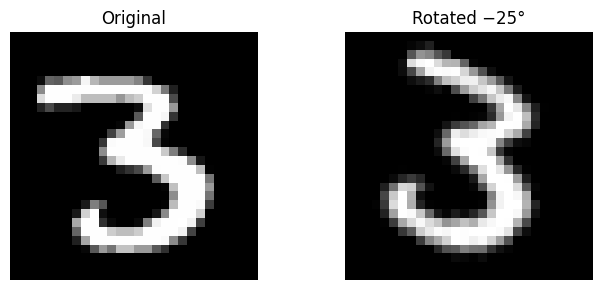

In [ ]:
def rotate_image(gray_image, degrees, center=None):
    h, w = gray_image.shape[:2]
    if center is None:
        center = (w / 2, h / 2)
    matrix = cv2.getRotationMatrix2D(center, degrees, 1.0)
    return cv2.warpAffine(gray_image, matrix, (w, h))

turned_digit = rotate_image(digit_float, -25)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(digit_float, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(turned_digit, cmap="gray")
axes[1].set_title("Rotated −25°")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Flip an image

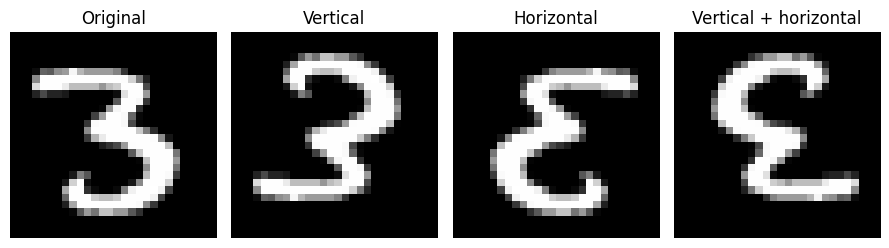

In [ ]:
flip_results = [
    (digit_float, "Original"),
    (cv2.flip(digit_float, 0), "Vertical"),
    (cv2.flip(digit_float, 1), "Horizontal"),
    (cv2.flip(digit_float, -1), "Vertical + horizontal")
]

fig, axes = plt.subplots(1, 4, figsize=(9, 3))
for ax, (shown_image, caption) in zip(axes, flip_results):
    ax.imshow(shown_image, cmap="gray")
    ax.set_title(caption)
    ax.axis("off")
plt.tight_layout()
plt.show()

Detect edges with Canny

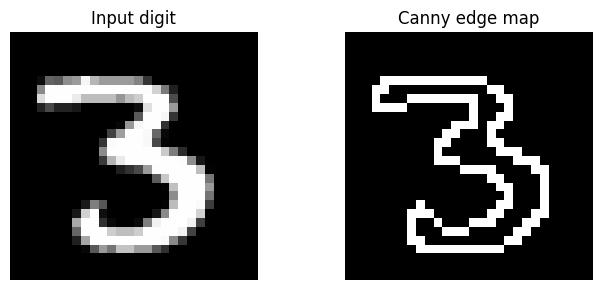

In [ ]:
digit_u8 = np.round(digit_float * 255).astype(np.uint8)

def find_edges(gray_image, low=40, high=120):
    #Return a binary edge map using the Canny detector.
    return cv2.Canny(gray_image, low, high)

edge_map = find_edges(digit_u8)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(digit_u8, cmap="gray")
axes[0].set_title("Input digit")
axes[1].imshow(edge_map, cmap="gray")
axes[1].set_title("Canny edge map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Convert between grayscale and BGR

In [ ]:
#BGR conversion adds three color channels to a grayscale image.
digit_u8 = np.round(digit_float * 255).astype(np.uint8)
color_view = cv2.cvtColor(digit_u8, cv2.COLOR_GRAY2BGR)

print("Grayscale dimensions:", digit_u8.shape)
print("Three-channel dimensions:", color_view.shape)

Grayscale dimensions: (28, 28)
Three-channel dimensions: (28, 28, 3)


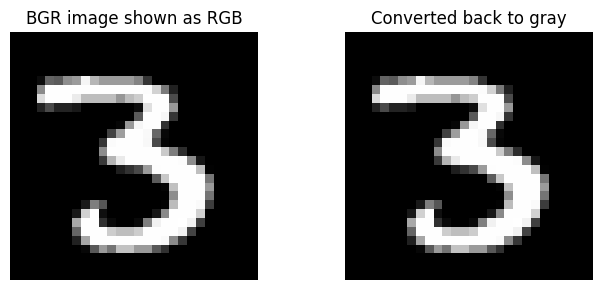

In [ ]:
gray_again = cv2.cvtColor(color_view, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(cv2.cvtColor(color_view, cv2.COLOR_BGR2RGB))
axes[0].set_title("BGR image shown as RGB")
axes[1].imshow(gray_again, cmap="gray")
axes[1].set_title("Converted back to gray")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Apply a circular mask

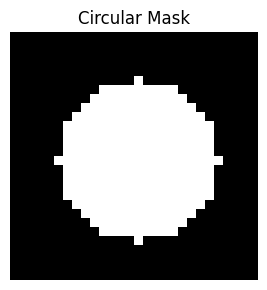

In [ ]:
digit_u8 = np.round(digit_float * 255).astype(np.uint8)
def circular_mask(img, center, radius):
    mask = np.zeros(img.shape[:2], dtype=np.uint8)
    cv2.circle(mask, center, radius, 255, -1)
    return mask

region_mask = circular_mask(digit_u8, (14, 14), 9)
masked_circle = cv2.bitwise_and(digit_u8, digit_u8, mask=region_mask)

plt.figure(figsize=(7, 3))

plt.imshow(region_mask, cmap="gray")
plt.title("Circular Mask")
plt.axis("off")

plt.tight_layout()
plt.show()


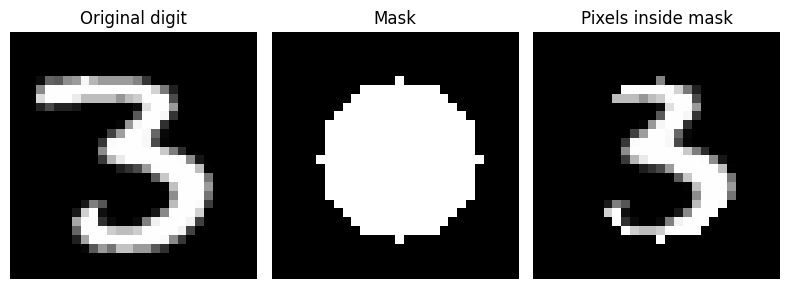

In [ ]:
region_only = cv2.bitwise_and(digit_u8, digit_u8, mask=region_mask)

fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, shown, label in zip(axes, [digit_u8, region_mask, region_only],
    ["Original digit", "Mask", "Pixels inside mask"]
):
    ax.imshow(shown, cmap="gray")
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

Invert a mask

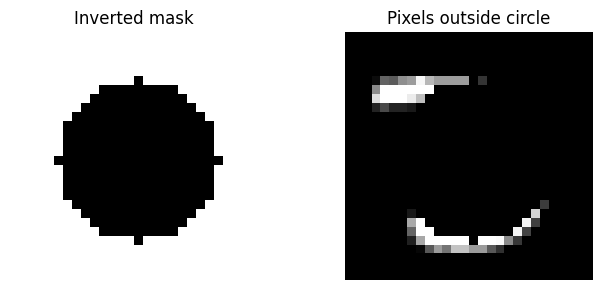

In [ ]:
outside_mask = cv2.bitwise_not(region_mask)
outside_region = cv2.bitwise_and(digit_u8, digit_u8, mask=outside_mask)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(outside_mask, cmap="gray")
axes[0].set_title("Inverted mask")
axes[1].imshow(outside_region, cmap="gray")
axes[1].set_title("Pixels outside circle")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Resize and scale an image

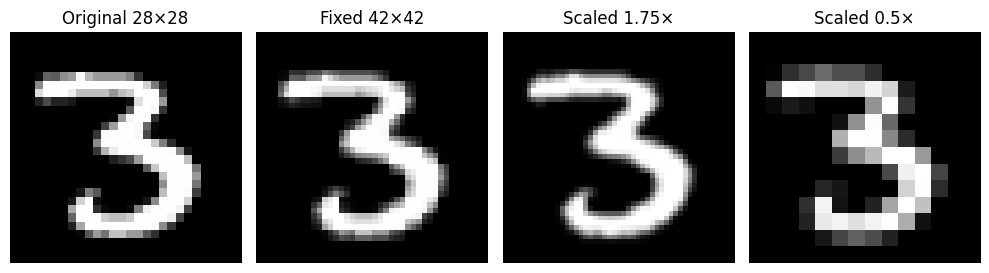

In [ ]:
digit_u8 = np.round(digit_float * 255).astype(np.uint8)

def resize_to(gray_image, new_width, new_height):
    return cv2.resize(gray_image, (new_width, new_height), interpolation=cv2.INTER_AREA)

def scale_by(gray_image, factor=1.5):
    height, width = gray_image.shape[:2]
    interpolation = cv2.INTER_CUBIC if factor > 1 else cv2.INTER_AREA
    return cv2.resize(
        gray_image, (int(width * factor), int(height * factor)),
        interpolation=interpolation
    )

larger_fixed = resize_to(digit_u8, 42, 42)
larger_scaled = scale_by(digit_u8, 1.75)
smaller_scaled = scale_by(digit_u8, 0.5)

preview_items = [
    (digit_u8, "Original 28×28"),
    (larger_fixed, "Fixed 42×42"),
    (larger_scaled, "Scaled 1.75×"),
    (smaller_scaled, "Scaled 0.5×")
]
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, (shown, caption) in zip(axes, preview_items):
    ax.imshow(shown, cmap="gray")
    ax.set_title(caption)
    ax.axis("off")
plt.tight_layout()
plt.show()

Binary thresholding


Threshold used: 100.0


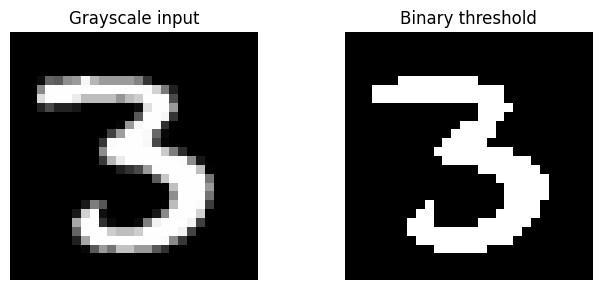

In [ ]:
digit_u8 = np.round(digit_float * 255).astype(np.uint8)

#Thresholding converts grayscale intensity into black-and-white pixels.
#It can make foreground digits easier to separate from the background.
threshold_value, binary_digit = cv2.threshold(
    digit_u8, 100, 255, cv2.THRESH_BINARY
)
print("Threshold used:", threshold_value)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(digit_u8, cmap="gray")
axes[0].set_title("Grayscale input")
axes[1].imshow(binary_digit, cmap="gray")
axes[1].set_title("Binary threshold")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Morphological dilation


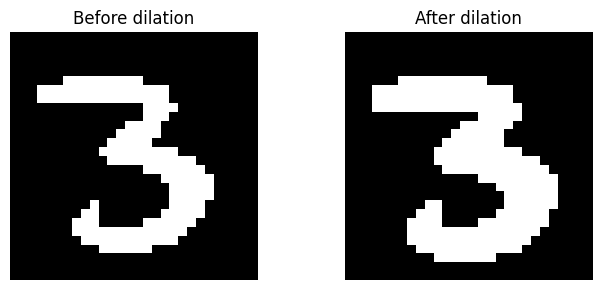

In [ ]:
#Dilation expands bright foreground regions using a small kernel. On a binary digit, it can thicken narrow strokes.
kernel = np.ones((2, 2), dtype=np.uint8)
thickened_digit = cv2.dilate(binary_digit, kernel, iterations=1)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(binary_digit, cmap="gray")
axes[0].set_title("Before dilation")
axes[1].imshow(thickened_digit, cmap="gray")
axes[1].set_title("After dilation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()